# 05 Cohort physics and the real analysis table

The physics model of notebooks 03-04 run on Piyush's whole cohort (A2-A4): 250 passive
objects at 400-800 km and 15 high-altitude controls at 1,040-1,211 km, Apr 2024 - Apr 2025.
Output: `data/processed/analysis_table.parquet` (one row per decay interval, `src/schema.py`),
rebuilt with `python -m src.build_table`.

Steps (`src/build_table.py`):
1. Density drivers for NRLMSISE-00 and MSIS 2.1 (actual ap) and MSIS 2.1 with each storm's
   quiet ap, cached in chunks of 10 objects (`data/processed/physics_chunks/`).
2. Hampel filter on the MSIS 2.1 residual. **Climb intervals are kept** (dropping only the upward
   TLE noise makes decay look too fast); the version without them is a check.
3. Drag sensitivity B per object on quiet fit intervals, block bootstrap by week, stability rule.
4. Gate: held-out quiet residual ~0, pooled and per object.
5. The table, May / Oct 2024 across the cohort, mean residual by event day.

All causal numbers here are **PRELIMINARY** (first run on real data).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import build_table as bt
from src import event_checks as ec
from src import event_study as es
from src.schema import main_sample, sample_report, save_table, high_alt_sample
from src.plots import (plot_drag_sensitivity, plot_holdout_t, plot_storm_residual_vs_alt,
                       plot_event_day_profile)

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")

intervals, tles, sw, storms = bt.load_inputs()
intervals = intervals.rename(columns={"alt_km": "alt_km_tle"})
bt.check_no_bridges(intervals, storms)
drivers = bt.cohort_drivers(tles, intervals, sw, storms, log=None)    # cached chunks
rates, drag = bt.cohort_physics(drivers, storms)
table = save_table(bt.assemble(rates, drag, sw, storms, tles))
# Check version: climb intervals dropped before the Hampel filter and the B fit
rates_nc, drag_nc = bt.cohort_physics(drivers, storms, drop_climbs=True)
table_nc = bt.assemble(rates_nc, drag_nc, sw, storms, tles)
print(f"{len(table):,} intervals, {table['norad_id'].nunique()} objects; without climbs {len(table_nc):,}")

199,580 intervals, 265 objects; without climbs 194,875


## 1. Sample: climbs, Hampel outliers and the main-sample filters

In [2]:
share = table.groupby("cohort_group")[["climb_flag", "hampel_outlier"]].mean()
print("Share of intervals that are climbs / Hampel outliers, by group:")
print(share)
print("Hampel outliers among climbs:", f"{table.loc[table['climb_flag'] == 1, 'hampel_outlier'].mean():.1%}")
sample_report(table)

Share of intervals that are climbs / Hampel outliers, by group:
               climb_flag  hampel_outlier
cohort_group                             
high_altitude      0.0448          0.0501
main               0.0223          0.0554
Hampel outliers among climbs: 64.5%


,filter,removed,share
0,active satellite,0,0
1,high-altitude control (alt >= 1000 km),11020,0.0552
2,ecc >= 0.01,0,0
3,TLE failed cleaning,10453,0.0524
4,no drag_sensitivity,0,0
5,kept,178107,0.892


## 2. Drag sensitivity B

B = sum(observed * dt) / sum(driver * dt) on the clean quiet 'fit' intervals (MSIS 2.1),
95% interval from 500 block-bootstrap draws of whole calendar weeks.
Rule (fixed before the run, `docs/PLAN.md`): **unstable** if fewer than 30 fit intervals,
bootstrap SE / B > 0.25, or the 95% interval reaches zero.

In [3]:
main_ids = table.loc[table["cohort_group"] == "main", "norad_id"].unique()
high_ids = table.loc[table["cohort_group"] == "high_altitude", "norad_id"].unique()
d = drag.assign(rel_se=drag["se"] / drag["B"])
print("Passive main objects with B <= 0:", int((d.loc[main_ids, "B"] <= 0).sum()), "of", len(main_ids))
print("Unstable: main", int(d.loc[main_ids, "unstable"].sum()), "/ high-altitude", int(d.loc[high_ids, "unstable"].sum()))
print("drag_source:", d["drag_source"].value_counts().to_dict())
d.loc[main_ids, ["B", "rel_se", "n_fit", "n_weeks"]].describe(percentiles=[0.05, 0.5, 0.95])

Passive main objects with B <= 0: 0 of 250
Unstable: main 0 / high-altitude 0
drag_source: {'fit': 265}


,B,rel_se,n_fit,n_weeks
count,250,250,250,250
mean,0.068,0.0316,203,39.7
std,0.0898,0.00852,29.4,1.55
min,0.00562,0.0163,119,34
5%,0.00598,0.0201,149,37
50%,0.0293,0.0302,209,40
95%,0.291,0.0459,246,42
max,0.591,0.0821,267,43


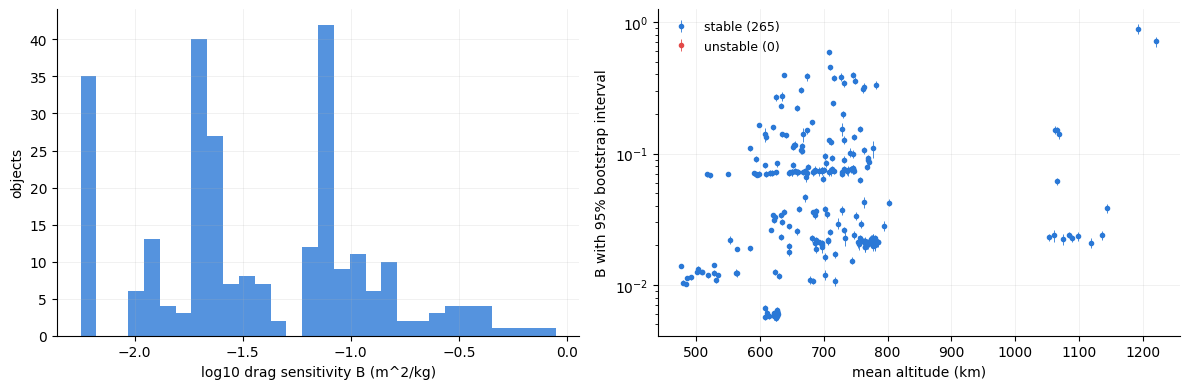

In [4]:
alt = table.groupby("norad_id")["alt_km"].mean()
fig = plot_drag_sensitivity(drag[drag["drag_source"] == "fit"], alt, out_path=RESULTS / "cohort_drag_sensitivity.png")

In [5]:
print("Unstable objects (all of them):")
d[d["unstable"] == 1].join(alt)

Unstable objects (all of them):


,B,se,ci_lo,ci_hi,n_weeks,n_fit,unstable,drag_source,rel_se,alt_km
norad_id,,,,,,,,,,


In [6]:
# B with and without the climb intervals: dropping the upward noise inflates B
ratio = (drag_nc["B"] / drag["B"]).loc[main_ids]
print(f"B without climbs / B with climbs: median {ratio.median():.4f}, 5-95% {ratio.quantile(0.05):.4f}-{ratio.quantile(0.95):.4f}")

B without climbs / B with climbs: median 1.0036, 5-95% 0.9767-1.0528


## 3. Gate: held-out quiet residual ~0

Every other quiet interval was held out of the B fit. Pooled: dt-weighted mean over all
held-out intervals of the main cohort, SE from weekly blocks (all objects of a week
together). Per object: mean / weekly-block SE. Decision rule: if the pooled residual is not ~0,
stop and fix B first.

In [7]:
gates = {}
for model in ["msis21", "nrlmsise00"]:
    for label, r in [("with climbs", rates), ("without climbs", rates_nc)]:
        pooled, per = bt.holdout_gate(r, model)
        gates[(model, label)] = (pooled, per)
pd.DataFrame({k: v[0] for k, v in gates.items()}).T

mean  se_block        t  unweighted_mean  intervals  objects  mean_obs
msis21     with climbs      -0.133      1.07   -0.124          -0.0846   5.07e+04      250     -50.6
           without climbs -0.00527      1.02 -0.00517          -0.0328   5.02e+04      250     -51.5
nrlmsise00 with climbs      -0.108      1.38  -0.0787           -0.062   5.07e+04      250     -50.6
           without climbs   0.0108      1.33  0.00814          -0.0105   5.02e+04      250     -51.5

Per-object t: mean 0.00, SD 0.82, |t| > 2: 6 of 250


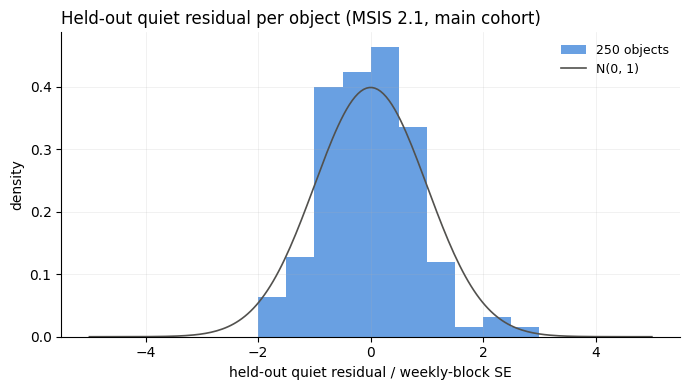

In [8]:
pooled, per = gates[("msis21", "with climbs")]
print(f"Per-object t: mean {per['t'].mean():.2f}, SD {per['t'].std():.2f}, |t| > 2: {(per['t'].abs() > 2).sum()} of {len(per)}")
fig = plot_holdout_t(per, "Held-out quiet residual per object (MSIS 2.1, main cohort)",
                     out_path=RESULTS / "cohort_holdout_t.png")

In [9]:
# High-altitude group: same check (their B is the quiet fit when stable)
pooled_h, per_h = bt.holdout_gate(rates, "msis21", groups=("high_altitude",))
pooled_h

mean                0.0297
se_block             0.069
t                     0.43
unweighted_mean    0.00796
intervals         2.98e+03
objects                 15
mean_obs             -2.27
dtype: float64

## 4. May 2024 and Oct 2024 across the cohort

Days 0..+3 after main_onset, per object: model error `Y_residual` (observed minus MSIS 2.1)
and total storm effect `Y_total` (observed minus MSIS 2.1 with the storm's quiet ap).
Negative = more decay than predicted.

In [10]:
key = ec.key_storm_ids(storms)
names = {sid: pd.Timestamp(storms.set_index("storm_id").loc[sid, "main_onset"]).strftime("%b %Y") for sid in key}
windows = {names[sid]: bt.storm_window_residual(table, sid) for sid in key}
pd.DataFrame({k: w[["Y_residual", "Y_total", "obs_decay", "pred_decay"]].median() for k, w in windows.items()}).T

,Y_residual,Y_total,obs_decay,pred_decay
May 2024,11.7,-4.75,-39.9,-54.5
Oct 2024,14.5,4.14,-26.4,-45.7


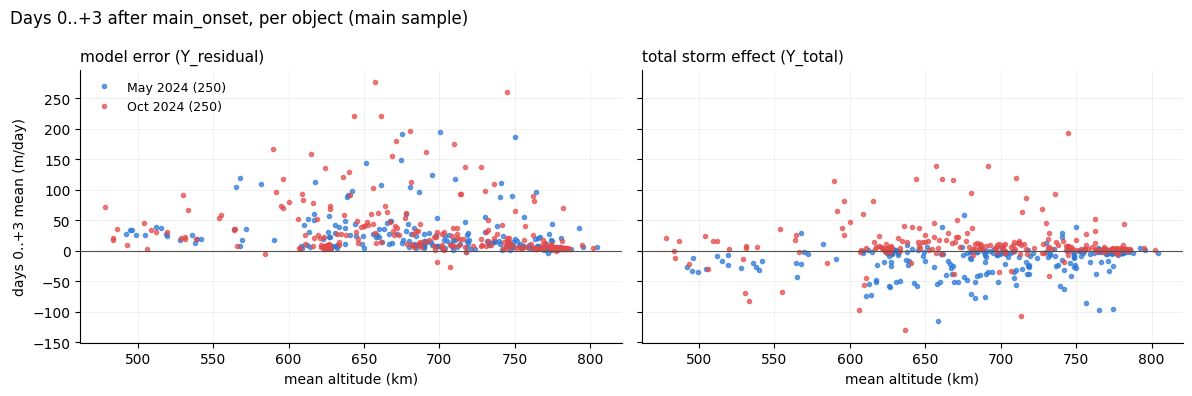

In [11]:
fig = plot_storm_residual_vs_alt(windows, "Days 0..+3 after main_onset, per object (main sample)",
                                 out_path=RESULTS / "cohort_may_oct_residuals.png")

## 5. Mean residual by event day

Main sample, dt-weighted mean per (storm, day), then mean over storms with the SE across
storms (storm = cluster). With all 20 storms and without May / Oct 2024.

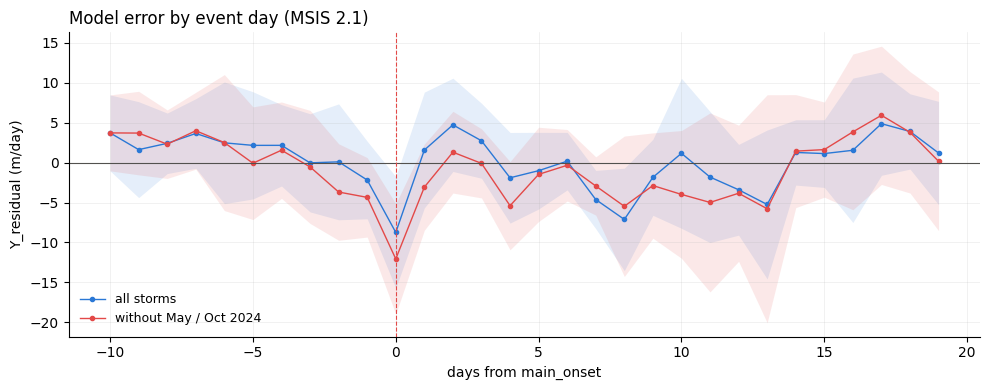

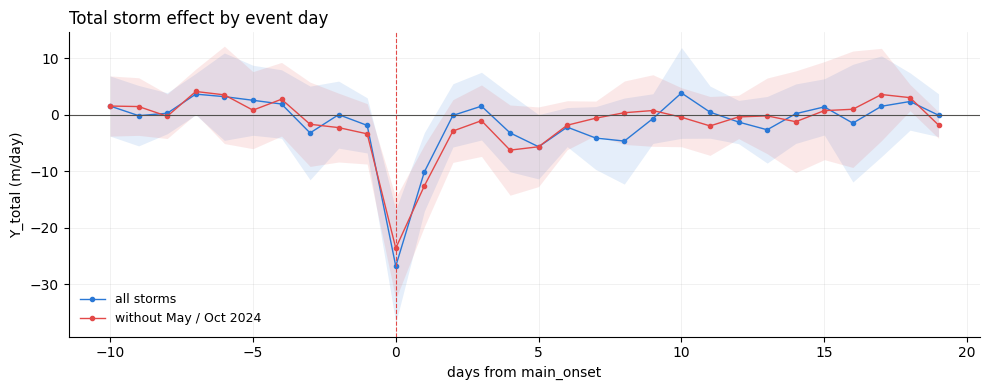

In [12]:
profiles = {o: {"all storms": bt.event_day_profile(table, o),
                "without May / Oct 2024": bt.event_day_profile(table, o, exclude=key)}
            for o in ["Y_residual", "Y_total"]}
fig = plot_event_day_profile(profiles["Y_residual"], "Model error by event day (MSIS 2.1)",
                             "Y_residual (m/day)", out_path=RESULTS / "cohort_event_day_residual.png")
fig = plot_event_day_profile(profiles["Y_total"], "Total storm effect by event day",
                             "Y_total (m/day)", out_path=RESULTS / "cohort_event_day_total.png")

In [13]:
pd.concat({f"{o}, {k}": p.loc[-3:5, "mean"] for o, d in profiles.items() for k, p in d.items()}, axis=1)

,"Y_residual, all storms","Y_residual, without May / Oct 2024","Y_total, all storms","Y_total, without May / Oct 2024"
day,,,,
-3,-0.033,-0.542,-3.2,-1.67
-2,0.0926,-3.69,0.038,-2.26
-1,-2.18,-4.36,-1.87,-3.37
0,-8.75,-12.1,-26.8,-23.6
1,1.57,-3.07,-10.1,-12.6
2,4.73,1.3,-0.0981,-2.87
3,2.73,-0.0983,1.54,-1.03
4,-1.9,-5.4,-3.19,-6.25
5,-1.01,-1.48,-5.66,-5.65


## 6. Smoke test of the causal pipeline (PRELIMINARY)

`python -m src.causal_run` on this table (event study for Y_total and Y_residual, placebo
dates, with/without May/Oct, contamination sensitivity, high-altitude negative control).
The offset ratio is skipped: no active satellites until B3. Below, the summary it wrote, and the
short-run effect with and without climb intervals.

In [14]:
summary = ROOT / "results" / "causal" / "summary.md"
print(summary.read_text() if summary.exists() else "Run python -m src.causal_run first")

# Track C results

## Sample

| Filter | Rows removed | Share |
|---|---|---|
| active satellite | 0 | 0.0% |
| high-altitude control (alt >= 1000 km) | 11,020 | 5.5% |
| ecc >= 0.01 | 0 | 0.0% |
| TLE failed cleaning | 10,453 | 5.2% |
| no drag_sensitivity | 0 | 0.0% |
| kept | 178,107 | 89.2% |

## Event study: Y_total

- 12 of 20 storms used (8 dropped as contaminated); 117128 of 265350 stacked rows dropped because they fall inside another storm's window.
- Short-run effect (days 0-2, m/day): -14.064 (95% CI -19.751 to -8.401).
- Placebo dates (main inference): 500 draws, mean 0.364, SD 1.270, p = 0.000.
- Pre-trend (RMS of days -10..-2 against the placebo draws): p = 0.410.

| Run | Short-run effect | 95% CI | Storms used |
|---|---|---|---|
| all storms | -14.064 | -19.751 to -8.401 | 12 |
| without 3,4,11 | -13.845 | -16.625 to -10.874 | 9 |
| active | -14.064 | -19.751 to -8.401 | 12 |
| (-3, 10) | -10.087 | -14.019 to -6.220 | 9 |

- High-altitude negative control: -0.687 (95% 

In [15]:
rows = {}
for label, t in [("with climbs", table), ("without climbs", table_nc)]:
    for o in ["Y_total", "Y_residual"]:
        res, rep = es.event_study(t, storms, o, n_boot=499)
        rows[(label, o)] = ec.short_run_effect(res)
pd.DataFrame(rows).T

est   se  ci_lo  ci_hi
with climbs    Y_total     -14.1 3.04  -19.8  -8.52
               Y_residual  0.153 1.63  -3.02   3.29
without climbs Y_total     -14.6 3.09  -20.4  -8.98
               Y_residual -0.238 1.46   -3.1   2.59

## Findings

All causal numbers **PRELIMINARY** (first real-data run, Oct 30).

- **Climbs**: 2.2% of main-cohort intervals are climbs; 64.5% of them are also Hampel outliers
  (tle_ok = 0), the rest stay in. Dropping them changes B by 0.4% (median) and the short-run
  effect from -14.1 to -14.6 m/day: no material bias either way, but keeping them is the
  unbiased choice.
- **Drag sensitivity**: positive and stable for all 250 passive objects (bootstrap SE / B
  median 3%, max 8%; 119+ fit intervals each). The 15 high-altitude objects also fit tightly
  (SE / B ~4%), so they keep their quiet fit instead of a fallback.
- **Gate passed**: held-out quiet residual -0.13 m/day (weekly-block SE 1.07, t = -0.12) pooled
  over 50,674 intervals, against a mean decay of -50.6 m/day; per-object t centred at 0 with
  SD 0.82, 6 of 250 beyond |t| = 2. Same for NRLMSISE-00 and without climbs.
- **May / Oct 2024**: MSIS 2.1 over-predicts days 0..+3 for almost every object (median
  Y_residual +12 / +15 m/day); the total storm effect over days 0..+3 is small (median
  -5 / +4 m/day). Notebook 04 traced this to TLE blur for May.
- **By event day**: Y_total drops to about -27 m/day on day 0 and is back near 0 by day 2, with or
  without May / Oct. Y_residual dips on day 0 (-9 m/day) and turns positive on days 1-3:
  MSIS 2.1 is about right on average, early on day 0 and slightly over afterwards.
- **Event study (12 clean storms)**: total storm effect, days 0-2, **-14.1 m/day (95% CI -19.8 to
  -8.4)**, placebo p < 0.002, pre-trend p = 0.41; -13.8 without May/Oct (storms 3, 4, 11 drop:
  the May filter also catches the moderate May 2 storm), -10.1 with the (-3, 10) rule. Model
  error Y_residual: +0.2 m/day (CI -3.2 to 3.2), placebo p = 0.88: no systematic MSIS 2.1 error
  in the short run. High-altitude control: Y_total -0.7 (CI -1.4 to 0.1), Y_residual -0.2
  (CI -0.7 to 0.3).